# Lean-15e : Monodromie et groupe fondamental — le cercle épointé à l'œuvre

**Navigation** : [<< Lean-15d Grothendieck en images](Lean-15d-Lean-Grothendieck-Visuel-Python.ipynb) · [Lean-16a Conway >>](Lean-16a-Conway-Man-and-Work.ipynb)

Volet preuve de la fenêtre « 7-bis » greffée dans [Lean-15](Lean-15-Grothendieck-Tribute.ipynb) (distillation #19333-G.beta, issues #21307/#21308). La monodromie y était nommée mais jamais définie ; ce carnet la définit, la calcule et la prouve sur l'exemple le plus simple qui la porte : la couverture `z ↦ z²` du plan complexe épointé. Le module `Grothendieck/Monodromie.lean` du lac `grothendieck_lean` porte les preuves formelles ; ce carnet les met en scène.


## L'idée en une phrase

Quand on fait tourner une boucle autour d'un point singulier, l'objet algébrique transporté le long de la boucle revient **transformé**. Cette transformation — la **monodromie** — encode la singularité. Ici : la racine carrée de `1` fait un tour complet du cercle et revient... en `-1`.

Le décor est la couverture universelle `exp : ℂ → ℂ*` : le plan complexe déroule le plan épointé, et chaque tour du cercle correspond à l'addition de `2πi` dans le revêtement. La boucle générateur de `π₁(ℂ*)` se relève depuis `1` en un chemin qui finit en `-1` : toute la monodromie de `z ↦ z²` est dans cette arrivée.


## Mise en place

Le carnet pilote le lac `grothendieck_lean` (module `Grothendieck.Monodromie`, issue #21308) via les utilitaires de la série. Sous Windows, l'exécution passe par WSL ; sous Linux, elle est native.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
from lean_notebook_utils import (
    find_lean_project, get_lean_project_path, run_lake, count_sorry, is_native_platform,
)

proj_win = find_lean_project('grothendieck_lean')
lean_path = get_lean_project_path('grothendieck_lean')
plat = 'natif' if is_native_platform() else 'WSL'
print(f'Chemin Windows : {proj_win}')
print(f'Chemin Lean    : {lean_path}')
print(f'Plateforme     : {plat}')


Chemin Windows : C:\dev\CoursIA-21308-monodromie\MyIA.AI.Notebooks\SymbolicAI\Lean\grothendieck_lean
Chemin Lean    : /mnt/c/dev/CoursIA-21308-monodromie/MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean
Plateforme     : WSL


Le module doit compiler sans aucun `sorry` avant toute lecture — c'est la vérification que les preuves ci-dessous sont bien dans le noyau.


In [2]:
build_timeout_s = 900  # premier build apres cache : long
rc, out, err = run_lake(lean_path, 'build Grothendieck.Monodromie', timeout=build_timeout_s)
print(f'lake build Grothendieck.Monodromie -> rc={rc}')
texte = (out or '') + (err or '')
print(texte[-800:] if texte else '(sortie vide : build deja chaud)')
assert rc == 0, 'le module doit compiler'


lake build Grothendieck.Monodromie -> rc=0
✔ [1945/1945] Built Grothendieck.Monodromie (287s)
Build completed successfully (1945 jobs).



In [3]:
# Helper : executer un snippet Lean dans le lac (import Grothendieck.Monodromie inclus).
_snip = proj_win / '.lake' / '_snippet_21308.lean'  # .lake est gitignore : jamais commite

def lean_snippet(src, timeout=300):
    _snip.write_text('import Grothendieck.Monodromie\n\n' + src, encoding='utf-8')
    rc, out, err = run_lake(lean_path, f'env lean .lake/_snippet_21308.lean', timeout=timeout)
    texte = (out or '') + (err or '')
    print(texte[-3000:] if texte else '(sortie vide)')
    return rc


## 1. La fibre au-dessus de 1 : l'objet transporté

La couverture `p : z ↦ z²` envoie `ℂ*` sur `ℂ*`. La **fibre** de `p` au-dessus de `1` est l'ensemble des `x` avec `x² = 1` : deux points, `1` et `-1`. C'est l'objet discret que la monodromie va permuter.


Fibre de z^2 = 1 : [-1.  1.]


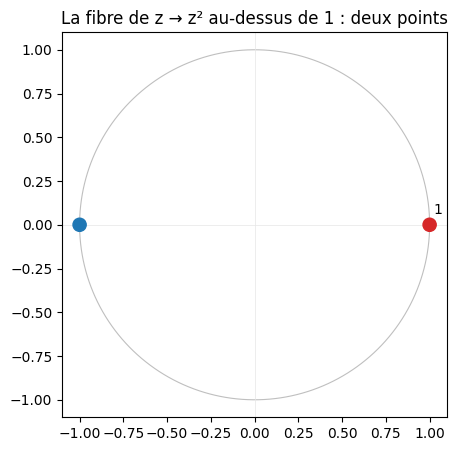

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fibre = np.roots([1, 0, -1])  # racines de z^2 - 1
print('Fibre de z^2 = 1 :', np.round(fibre, 10))

fig, ax = plt.subplots(figsize=(5.6, 5.0))
theta = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(theta), np.sin(theta), color='0.75', lw=0.8)  # cercle unite
ax.scatter(fibre.real, fibre.imag, s=90, color=['#1f77b4', '#d62728'], zorder=3)
ax.annotate('1', (1.02, 0.06)); ax.annotate('-1', (-1.12, 0.06))
ax.set_aspect('equal'); ax.axhline(0, color='0.9', lw=0.5); ax.axvline(0, color='0.9', lw=0.5)
ax.set_title('La fibre de z → z² au-dessus de 1 : deux points')
plt.show()


### Lecture du résultat

Deux points, pas un : la fibre compte le degré de la couverture (ici 2). Le module formalise exactement ce fait.


In [5]:
# La fibre, formellement : exactement {1, -1}, par factorisation (x-1)(x+1) = 0.
rc = lean_snippet(
    '#check @Grothendieck.fiber_sq_one\n'
    '#print axioms Grothendieck.fiber_sq_one\n'
    'example : (-1 : ℂ) ^ 2 = 1 := by norm_num\n'
)
assert rc == 0


Grothendieck.fiber_sq_one : ∀ (x : ℂ), x ^ 2 = 1 ↔ x = 1 ∨ x = -1
'Grothendieck.fiber_sq_one' depends on axioms: [propext, Classical.choice, Quot.sound]



## 2. La boucle générateur et son relèvement

La boucle `γ : t ↦ exp(2πi·t)` fait un tour complet du cercle. Son **relèvement** par la racine carrée part de `1` et n fait qu'un demi-tour : `γ̃ : t ↦ exp(πi·t)`. Il couvre `γ` point par point (`γ̃² = γ`) — et son arrivée est le cœur du phénomène.


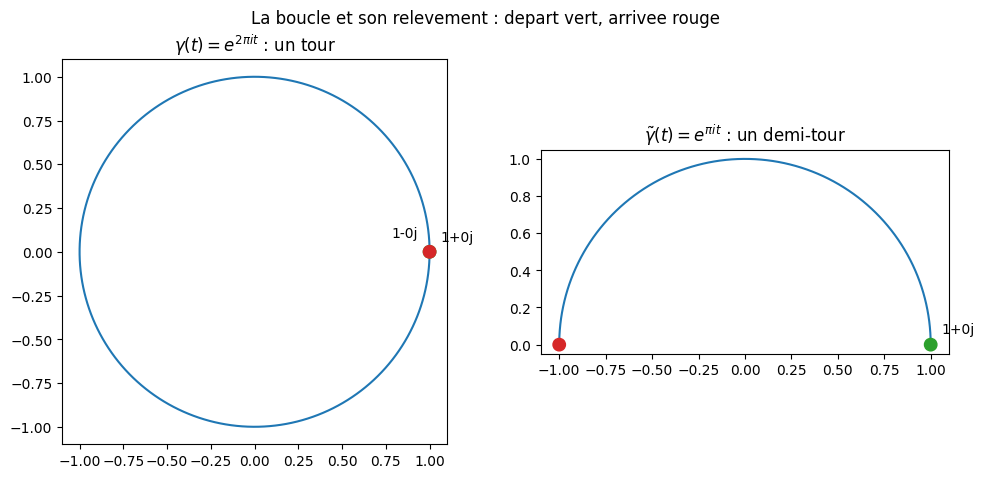

Arrivee du relevement : (-1+0j)


In [6]:
t = np.linspace(0, 1, 200)
gamma = np.exp(2j * np.pi * t)   # la boucle : un tour complet
gamma_tilde = np.exp(1j * np.pi * t)  # le relevement : un demi-tour

fig, (g, d) = plt.subplots(1, 2, figsize=(11.6, 5.0))
for a, z, titre in ((g, gamma, r'$\gamma(t) = e^{2\pi i t}$ : un tour'),
                    (d, gamma_tilde, r'$\tilde\gamma(t) = e^{\pi i t}$ : un demi-tour')):
    a.plot(z.real, z.imag, color='#1f77b4')
    a.scatter([z[0].real, z[-1].real], [z[0].imag, z[-1].imag], s=80, color=['#2ca02c', '#d62728'], zorder=3)
    a.annotate(f'{z[0]:.0f}', (z[0].real + 0.06, z[0].imag + 0.06))
    a.annotate(f'{z[-1]:.0f}', (z[-1].real - 0.22, z[-1].imag + 0.08))
    a.set_aspect('equal'); a.set_title(titre)
plt.suptitle('La boucle et son relevement : depart vert, arrivee rouge')
plt.show()
print('Arrivee du relevement :', np.round(gamma_tilde[-1], 10))


### Lecture du résultat

À gauche, la boucle revient à son départ (c'est un lacet). À droite, le relèvement **part de 1 et arrive en -1** : la racine carrée transportée autour du cercle change de signe. C'est LA monodromie, vue sur la figure.


In [7]:
# Le relevement, formellement : il couvre la boucle et finit en -1.
rc = lean_snippet(
    '#check @Grothendieck.generatorLoop\n'
    '#check @Grothendieck.generatorLift\n'
    '#check @Grothendieck.lift_covers_loop\n'
    '#check @Grothendieck.lift_one\n'
    '#print axioms Grothendieck.lift_one\n'
)
assert rc == 0


Grothendieck.generatorLoop : ℝ → ℂ
Grothendieck.generatorLift : ℝ → ℂ
Grothendieck.lift_covers_loop : ∀ (t : ℝ), Grothendieck.generatorLift t ^ 2 = Grothendieck.generatorLoop t
Grothendieck.lift_one : Grothendieck.generatorLift 1 = -1
'Grothendieck.lift_one' depends on axioms: [propext, Classical.choice, Quot.sound]



## 3. La monodromie comme action sur la fibre

Transporter la fibre le long de la boucle = permuter ses deux points. Le relèvement envoie `1 ↦ -1`, donc la monodromie est la **transposition** `x ↦ -x` — d'ordre exactement 2.


In [8]:
# La transposition sur la base (1, -1) de la fibre.
M = np.array([[0, 1], [1, 0]])  # e1 (=1) et e2 (=-1) s'echangent
print('M @ (1, 0) =', M @ np.array([1, 0]), ' : le point 1 va en -1')
print('M @ M      ='); print(M @ M, ' : involution, ordre 2')


M @ (1, 0) = [0 1]  : le point 1 va en -1
M @ M      =
[[1 0]
 [0 1]]  : involution, ordre 2


### Lecture du résultat

La matrice échange les deux points et son carré est l'identité. Le module formalise la même action comme fonction `x ↦ -x` préservant la fibre, et relie les deux points de vue : la monodromie du générateur envoie le départ du relèvement sur son arrivée.


In [9]:
rc = lean_snippet(
    '#check @Grothendieck.monodromySq\n'
    '#check @Grothendieck.monodromySq_mem_fiber\n'
    '#check @Grothendieck.monodromySq_sq\n'
    '#check @Grothendieck.monodromy_of_generator\n'
    '#print axioms Grothendieck.monodromy_of_generator\n'
)
assert rc == 0


Grothendieck.monodromySq : ℂ → ℂ
@Grothendieck.monodromySq_mem_fiber : ∀ {x : ℂ}, x ^ 2 = 1 → Grothendieck.monodromySq x ^ 2 = 1
Grothendieck.monodromySq_sq : ∀ (x : ℂ), Grothendieck.monodromySq (Grothendieck.monodromySq x) = x
Grothendieck.monodromy_of_generator : Grothendieck.monodromySq (Grothendieck.generatorLift 0) =
  Grothendieck.generatorLift 1
'Grothendieck.monodromy_of_generator' depends on axioms: [propext, Classical.choice, Quot.sound]



## 4. Quasi-unipotence : le calcul, puis la frontière

Le théorème de quasi-unipotence de Grothendieck (SGA 7, XII) porte sur une famille lisse au-dessus d'un disque épointé : un certain pouvoir de sa monodromie est unipotent. **Mathlib ne le formalise pas** (aucune théorie des familles lisses paramétrées ni de monodromie ℓ-adique), et ce carnet ne le remplace pas : notre monodromie est d'ordre fini (2), cas d'école de l'implication algébrique élémentaire — opérateur d'ordre fini ⇒ valeurs propres racines de l'unité — que le module consigne comme `Prop` documentaire (`finiteOrderEigenvaluesRootsOfUnity`) et que l'exemple vérifie.


In [10]:
print('Valeurs propres de la transposition :', np.linalg.eigvals(M))
print('1 et -1 sont racines de l unites : (1)^2 =', 1**2, ', (-1)^2 =', (-1)**2)
print('M^2 = I : la puissance deux est unipotente (trivialement)')


Valeurs propres de la transposition : [ 1. -1.]
1 et -1 sont racines de l unites : (1)^2 = 1 , (-1)^2 = 1
M^2 = I : la puissance deux est unipotente (trivialement)


### Lecture du résultat

Sur cet exemple : ordre 2, valeurs propres `{1, -1}` toutes racines de l'unité, `M² = I` unipotent (trivialement : identité). Dans cet exemple, M²=I. La conclusion générale visée est seulement qu'une puissance de la monodromie est unipotent ; elle n'impose ni l'ordre 2 ni une puissance égale à l'identité.


In [11]:
rc = lean_snippet(
    '#check @Grothendieck.eigenvalue_neg_one_sq\n'
    '#check @Grothendieck.monodromySq_pow_two_eq_id\n'
    '#check @Grothendieck.finiteOrderEigenvaluesRootsOfUnity\n'
)
assert rc == 0


Grothendieck.eigenvalue_neg_one_sq : (-1) ^ 2 = 1
Grothendieck.monodromySq_pow_two_eq_id : ∀ (x : ℂ), Grothendieck.monodromySq (Grothendieck.monodromySq x) = x
Grothendieck.finiteOrderEigenvaluesRootsOfUnity : Prop



## 5. Intégrité formelle

Le module ne doit contenir aucun `sorry`, et aucun théorème cité ne peut en dépendre transitivement (`sorryAx`).


In [12]:
n_sorry = count_sorry(str(proj_win), 'Grothendieck/')
print(f'sorry (code reel) dans Grothendieck/ du lac : {n_sorry}')
rc = lean_snippet(
    '#print axioms Grothendieck.fiber_sq_one\n'
    '#print axioms Grothendieck.lift_one\n'
    '#print axioms Grothendieck.monodromy_of_generator\n'
)
assert rc == 0


sorry (code reel) dans Grothendieck/ du lac : 0


'Grothendieck.fiber_sq_one' depends on axioms: [propext, Classical.choice, Quot.sound]
'Grothendieck.lift_one' depends on axioms: [propext, Classical.choice, Quot.sound]
'Grothendieck.monodromy_of_generator' depends on axioms: [propext, Classical.choice, Quot.sound]



### Lecture du résultat

Chaque `#print axioms` ne doit citer que les axiomes standard de Lean (`propext`, `Classical.choice`, `Quot.sound`) — jamais `sorryAx`. La frontière est nette : `finiteOrderEigenvaluesRootsOfUnity` est l'**implication algébrique** élémentaire (opérateur d'ordre fini ⇒ valeurs propres racines de l'unité), consignée et non prouvée ici ; le **théorème géométrique** de SGA 7 — familles lisses sur disque épointé, conclusion unipotente — reste hors Mathlib et hors du module.


## 6. Ce que ce carnet a établi

1. La fibre de `z ↦ z²` au-dessus de 1 est `{1, -1}` (formel : `fiber_sq_one`).
2. Le relèvement de la boucle générateur part de 1 et **arrive en -1** (`lift_one`) — la monodromie visible.
3. La monodromie est la transposition `x ↦ -x`, involution préservant la fibre (`monodromy_of_generator`).
4. Ordre 2, valeur propre racine de l'unité : l'implication algébrique (opérateur d'ordre fini ⇒ racines de l'unité) **vérifiée** sur l'exemple ; le théorème géométrique général (SGA 7) reste hors Mathlib et n'est pas revendiqué.


## 7. Pour aller plus loin

- **Le pont trèfle** : la même monodromie tord le tore au-dessus de la cubique cuspidale `y² = x³` et fabrique le nœud trèfle — déroulé côté preuves dans [knot_lean](KNOTS/) via la greffe #19356.
- **La fenêtre 7-bis** de [Lean-15](Lean-15-Grothendieck-Tribute.ipynb) situe la monodromie dans le paysage Grothendieck (Weil II, polynôme d'Alexander).
- **SGA 7, XII** : l'énoncé original de la quasi-unipotence, et *Weil II* (Deligne 1980) pour son rôle central.


## 8. Exercices

Trois exercices prolongent le carnet sur la couverture `z ↦ z³` puis sur la lecture générale.


### Exercice 1 — la fibre de z ↦ z³

Construire la fibre de `z ↦ z³` au-dessus de 1 (trois racines de l'unité), afficher ses points, et dire quelle permutation la monodromie du générateur induit (le relèvement `t ↦ exp(2πi·t/3)` envoie 1 sur `exp(2πi/3)` : un 3-cycle).


In [13]:
# Exercice 1 : fibre de z^3 = 1 et monodromie d'ordre 3
# TODO etudiant : calculer les racines, tracer la fibre, identifier le 3-cycle
# Indice : np.roots([1, 0, 0, -1]) ; le relevement t -> exp(2j*pi*t/3)
resultat = None  # TODO etudiant
print('Exercice a completer')


Exercice a completer


### Exercice 2 — le relèvement de la boucle double

Que devient le relèvement de la boucle parcourue **deux fois** (`t ↦ exp(4πi·t)`), toujours pour `z ↦ z²` ? Partant de 1, où arrive-t-on ? (C'est la question de l'itération de la monodromie — et la raison de son ordre exact.)


In [14]:
# Exercice 2 : relevement de la boucle double
# TODO etudiant : tracer gamma_2(t) = exp(4j*pi*t) et son relevement exp(2j*pi*t)
# Indice : l'arrivee du relevement repond a la question de l'ordre
resultat = None  # TODO etudiant
print('Exercice a completer')


Exercice a completer


### Exercice 3 — valeurs propres et racines de l'unité

Pour `z ↦ zⁿ` (fibre à n points), la monodromie est un n-cycle — d'ordre fini. Calculer numériquement ses valeurs propres pour n = 3, 4, 5 et vérifier que ce sont toutes des racines de l'unité — la conclusion de l'implication consignée (`finiteOrderEigenvaluesRootsOfUnity`) sur cette famille d'exemples.


In [15]:
# Exercice 3 : valeurs propres des monodromies d'ordre n = 3, 4, 5
# TODO etudiant : matrice du n-cycle, np.linalg.eigvals, verifier |lambda|^n = 1
# Indice : les valeurs propres d'un n-cycle sont exp(2j*pi*k/n), k = 0..n-1
resultat = None  # TODO etudiant
print('Exercice a completer')


Exercice a completer
